# Detección de Fraude Financiero con Machine Learning
## Notebook 03 · Modelado
**Proyecto Final – Minería de Datos · Metodología CRISP-DM (fase 4)**

| Modelo | Familia | Rol en el proyecto |
|---|---|---|
| Regresión Logística | Lineal | Línea base: los modelos complejos deben superarla |
| Random Forest | *Bagging* | Requerimiento obligatorio |
| XGBoost | *Boosting* | Requerimiento obligatorio |
| Stacking (RF + XGB) | *Ensemble* | Continuidad con el ejemplo de clase |
| DNN | Red neuronal profunda | Requerimiento obligatorio |
| Autoencoder | Red neuronal no supervisada | Detección de anomalías (requerimiento obligatorio) |

**Procedimiento**
1. **Estrategia de balanceo.** Cada modelo se entrena sin balanceo, con pesos de clase y con SMOTE, usando hiperparámetros por defecto. Se compara el PR-AUC en **validación**.
2. **Ajuste de hiperparámetros.** Con la mejor estrategia de cada modelo se ejecuta `RandomizedSearchCV` con validación cruzada estratificada de 3 pliegues **solo sobre entrenamiento**. El escalador y SMOTE están dentro del pipeline, así que se reajustan en cada pliegue.
3. **Guardado.** Se guardan los modelos y sus puntajes en validación y prueba. **El conjunto de prueba no se mira en este notebook**: sus métricas se calculan en la Fase 5.

La métrica de selección es el **PR-AUC** (*Average Precision*): resume la curva Precision-Recall y, a diferencia del ROC-AUC, no se infla por el gran número de transacciones legítimas.

In [1]:
import sys
import time
from pathlib import Path

# Permite importar src/ tanto si el kernel arranca en notebooks/ como en la raíz del proyecto
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(RAIZ))

import os
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")   # menos mensajes de TensorFlow

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score

from src.config import (
    FIG_DIR, RANDOM_STATE, BALANCEOS, COLORES_BALANCEO, PALETA_CLASES, NOMBRES_CLASES,
    fijar_semillas,
)
from src.data_preprocessing import RUTA_PREPROCESADOR, cargar_splits, separar_xy
import src.train_models as tm

fijar_semillas()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "grid.alpha": 0.35, "grid.linewidth": 0.6})

def guardar_figura(nombre):
    """Guarda la figura actual en reports/figures para el artículo IEEE."""
    plt.savefig(FIG_DIR / nombre, bbox_inches="tight", dpi=150)

# --- Datos de la Fase 3 ---
splits = cargar_splits()
X_train, y_train = separar_xy(splits["train"])
X_val, y_val = separar_xy(splits["val"])
X_test, y_test = separar_xy(splits["test"])

# Las redes neuronales reciben los datos ya escalados con el preprocesador de la Fase 3
preprocesador = joblib.load(RUTA_PREPROCESADOR)
Xs_train, Xs_val, Xs_test = (preprocesador.transform(X) for X in (X_train, X_val, X_test))

# Puntajes de cada modelo (validación para decidir; prueba se guarda para la Fase 5)
puntajes_val, puntajes_test = {}, {}
def registrar(nombre, p_val, p_test):
    puntajes_val[nombre], puntajes_test[nombre] = np.asarray(p_val), np.asarray(p_test)
    return {"PR-AUC (val)": average_precision_score(y_val, p_val),
            "ROC-AUC (val)": roc_auc_score(y_val, p_val)}

RAZON = tm.razon_desbalance(y_train)
print(f"Entrenamiento: {len(y_train):,} filas, {int(y_train.sum())} fraudes | razón de desbalance = {RAZON:.0f}")

Entrenamiento: 170,235 filas, 284 fraudes | razón de desbalance = 598


---
## 4.1 Técnicas de modelado

- **Regresión Logística.** Modelo lineal que estima $P(\text{fraude}) = \sigma(w^\top x + b)$. Rápido e interpretable; sirve de referencia.
- **Random Forest (*bagging*).** Entrena muchos árboles de decisión sobre muestras *bootstrap* y subconjuntos aleatorios de variables, y promedia sus votos. Promediar árboles poco correlacionados reduce la varianza.
- **XGBoost (*boosting*).** Construye árboles en secuencia: cada árbol nuevo corrige los errores (gradientes de la pérdida) de los anteriores. Incluye regularización L2 (`reg_lambda`) y poda (`gamma`).
- **Stacking.** Un meta-modelo (Regresión Logística) aprende a combinar las probabilidades de RF y XGBoost, generadas fuera de pliegue para no sobreajustar.
- **DNN.** Red densa con capas ReLU, *Batch Normalization*, *Dropout* y salida sigmoide; *early stopping* sobre el PR-AUC de validación.
- **Autoencoder.** Red que comprime y reconstruye la transacción. Se entrena **solo con transacciones legítimas**; un fraude, distinto de lo aprendido, se reconstruye con mayor error. El **error de reconstrucción** es el puntaje de anomalía.

**Estrategias de balanceo**

| Estrategia | Regresión Logística | Random Forest | XGBoost | DNN |
|---|---|---|---|---|
| Sin balanceo | — | — | — | — |
| Pesos de clase | `class_weight="balanced"` | `class_weight="balanced_subsample"` | `scale_pos_weight` | `class_weight` en `fit()` |
| SMOTE | SMOTE 0,1 en el pipeline | SMOTE 0,1 en el pipeline | SMOTE 0,1 en el pipeline | SMOTE 0,1 sobre entrenamiento |

---
## 4.2 Paso 1 · Comparación de estrategias de balanceo

In [2]:
inicio = time.perf_counter()
tabla_balanceo, modelos_variantes = tm.comparar_balanceo(list(tm.TIPOS), X_train, y_train, X_val, y_val)

# Se guardan los puntajes de cada variante para comparar con y sin SMOTE también en prueba (Fase 5)
for (modelo, variante), m in modelos_variantes.items():
    registrar(f"{modelo} · {variante}", tm.puntaje(m, X_val), tm.puntaje(m, X_test))

display(tabla_balanceo.pivot(index="Modelo", columns="Balanceo", values="PR-AUC (val)")
        [BALANCEOS].loc[list(tm.TIPOS.values())].round(4))
print(f"Tiempo total: {time.perf_counter() - inicio:.0f} s")

Balanceo,Sin balanceo,Pesos de clase,SMOTE
Modelo,,,
Regresión Logística,0.8012,0.7899,0.8031
Random Forest,0.8740,0.8747,0.8751
XGBoost,0.8869,0.8827,0.8688


Tiempo total: 82 s


Mejor estrategia por modelo (PR-AUC en validación): {'Random Forest': 'SMOTE', 'Regresión Logística': 'SMOTE', 'XGBoost': 'Sin balanceo'}


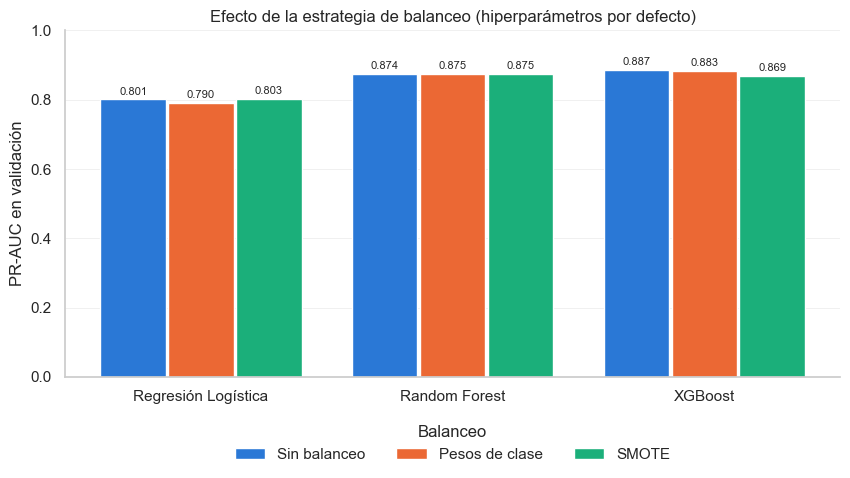

In [3]:
mejor_balanceo = (tabla_balanceo.loc[tabla_balanceo.groupby("Modelo")["PR-AUC (val)"].idxmax()]
                  .set_index("Modelo")["Balanceo"].to_dict())
print("Mejor estrategia por modelo (PR-AUC en validación):", mejor_balanceo)

fig, ax = plt.subplots(figsize=(10, 4.5))
modelos_orden = list(tm.TIPOS.values())
ancho = 0.26
x = np.arange(len(modelos_orden))
for i, variante in enumerate(BALANCEOS):
    valores = (tabla_balanceo[tabla_balanceo["Balanceo"] == variante]
               .set_index("Modelo").loc[modelos_orden, "PR-AUC (val)"])
    barras = ax.bar(x + (i - 1) * (ancho + 0.01), valores, width=ancho,
                    color=COLORES_BALANCEO[variante], label=variante)
    ax.bar_label(barras, fmt="%.3f", fontsize=8, padding=2)
ax.set_xticks(x, modelos_orden)
ax.set_ylim(0, 1)
ax.set(ylabel="PR-AUC en validación", title="Efecto de la estrategia de balanceo (hiperparámetros por defecto)")
ax.legend(title="Balanceo", loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
ax.grid(axis="x", visible=False)
guardar_figura("11_comparacion_balanceo.png")
plt.show()

---
## 4.3 Paso 2 · Ajuste de hiperparámetros

`RandomizedSearchCV` prueba combinaciones aleatorias del espacio de búsqueda (más eficiente que una rejilla completa cuando hay muchos hiperparámetros) y las evalúa con validación cruzada estratificada de 3 pliegues sobre entrenamiento. Si la estrategia ganadora es SMOTE, su proporción (`sampling_strategy`) también se ajusta; si son pesos de clase en XGBoost, se ajusta `scale_pos_weight`.

| Modelo | Hiperparámetros explorados | Combinaciones |
|---|---|---|
| Regresión Logística | `C` (regularización) | 10 |
| Random Forest | `n_estimators`, `max_depth`, `min_samples_leaf`, `max_features`, `max_samples` | 8 |
| XGBoost | `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`, `min_child_weight`, `gamma`, `reg_lambda` | 20 |

Random Forest tiene menos combinaciones porque cada ajuste tarda bastante más.

In [4]:
N_ITER = {"logistica": 10, "random_forest": 8, "xgboost": 20}
modelos_finales, busquedas = {}, {}

def ajustar_y_guardar(tipo):
    nombre = tm.TIPOS[tipo]
    variante = mejor_balanceo[nombre]
    inicio = time.perf_counter()
    # La logística es rápida: se paraleliza la búsqueda. RF y XGBoost ya usan todos los núcleos.
    busqueda = tm.ajustar_hiperparametros(tipo, variante, X_train, y_train, N_ITER[tipo],
                                          n_jobs=-1 if tipo == "logistica" else 1)
    modelo = busqueda.best_estimator_
    modelos_finales[nombre], busquedas[nombre] = modelo, busqueda
    metricas = registrar(nombre, tm.puntaje(modelo, X_val), tm.puntaje(modelo, X_test))
    tm.guardar_modelo(nombre, modelo, "pipeline", f"{tipo}.joblib", balanceo=variante,
                      params=tm.limpiar_parametros(busqueda.best_params_),
                      pr_auc_cv=float(busqueda.best_score_), pr_auc_val=float(metricas["PR-AUC (val)"]))
    print(f"{nombre} ({variante}) | PR-AUC CV = {busqueda.best_score_:.4f} | "
          f"PR-AUC val = {metricas['PR-AUC (val)']:.4f} | {time.perf_counter() - inicio:.0f} s")
    print("Mejores hiperparámetros:", tm.limpiar_parametros(busqueda.best_params_))
    display(tm.resumen_busqueda(busqueda).round(4))

ajustar_y_guardar("logistica")

Regresión Logística (SMOTE) | PR-AUC CV = 0.7341 | PR-AUC val = 0.8016 | 12 s
Mejores hiperparámetros: {'modelo__C': 0.03148911647956861, 'smote__sampling_strategy': 0.05}


,C,smote__sampling_strategy,PR-AUC CV (media),PR-AUC CV (desv.),Tiempo ajuste (s)
0,0.0315,0.05,0.7341,0.0432,2.1033
2,0.2481,0.25,0.7320,0.0382,3.5941
6,0.6797,0.10,0.7319,0.0409,2.7818
8,2.1368,0.10,0.7318,0.0409,2.4648
5,0.0216,0.50,0.7312,0.0397,2.9589


In [5]:
ajustar_y_guardar("random_forest")

Random Forest (SMOTE) | PR-AUC CV = 0.8348 | PR-AUC val = 0.8796 | 697 s
Mejores hiperparámetros: {'modelo__max_depth': None, 'modelo__max_features': 0.3, 'modelo__max_samples': 0.5, 'modelo__min_samples_leaf': 3, 'modelo__n_estimators': 299, 'smote__sampling_strategy': 0.05}


,max_depth,max_features,max_samples,min_samples_leaf,n_estimators,smote__sampling_strategy,PR-AUC CV (media),PR-AUC CV (desv.),Tiempo ajuste (s)
2,None,0.3,0.5,3,299,0.05,0.8348,0.0615,40.2071
1,None,sqrt,0.5,3,224,0.25,0.8324,0.0582,23.2450
4,12,0.3,0.3,4,238,0.05,0.8323,0.0646,20.3050
7,None,sqrt,0.3,3,284,0.05,0.8318,0.0641,27.4317
6,12,sqrt,0.5,3,257,0.25,0.8301,0.0556,18.5708


In [6]:
ajustar_y_guardar("xgboost")

XGBoost (Sin balanceo) | PR-AUC CV = 0.8372 | PR-AUC val = 0.8892 | 260 s
Mejores hiperparámetros: {'modelo__colsample_bytree': 0.9330880728874675, 'modelo__gamma': 1.2022300234864176, 'modelo__learning_rate': 0.08341106432362087, 'modelo__max_depth': 7, 'modelo__min_child_weight': 2, 'modelo__n_estimators': 543, 'modelo__reg_lambda': 4.622589001020832, 'modelo__subsample': 0.6849356442713105}


,colsample_bytree,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda,subsample,PR-AUC CV (media),PR-AUC CV (desv.),Tiempo ajuste (s)
1,0.9331,1.2022,0.0834,7,2,543,4.6226,0.6849,0.8372,0.0720,3.2794
15,0.6144,0.1540,0.0238,6,2,756,0.3902,0.6422,0.8366,0.0678,9.4709
2,0.5909,0.3668,0.0249,7,4,760,1.1209,0.7599,0.8359,0.0719,3.5784
12,0.6626,1.4592,0.0675,5,3,661,4.9869,0.8887,0.8352,0.0691,5.9934
7,0.5157,1.6846,0.0385,4,6,469,2.8480,0.7306,0.8351,0.0708,1.9775


---
## 4.4 Stacking (RF + XGB)
Se retoma la idea del ejemplo de clase, con tres mejoras: los modelos base son los pipelines ya ajustados (cada uno con su escalado y su estrategia de balanceo), las probabilidades del nivel 1 se generan con validación cruzada **estratificada** y el meta-modelo combina **probabilidades** (`stack_method="predict_proba"`).

In [7]:
inicio = time.perf_counter()
stacking = tm.crear_stacking(modelos_finales["Random Forest"], modelos_finales["XGBoost"]).fit(X_train, y_train)
metricas = registrar("Stacking (RF + XGB)", tm.puntaje(stacking, X_val), tm.puntaje(stacking, X_test))
tm.guardar_modelo("Stacking (RF + XGB)", stacking, "pipeline", "stacking.joblib",
                  pr_auc_val=float(metricas["PR-AUC (val)"]))
pesos_meta = dict(zip(["RF", "XGB"], stacking.final_estimator_.coef_.ravel().round(3)))
print(f"PR-AUC val = {metricas['PR-AUC (val)']:.4f} | pesos del meta-modelo: {pesos_meta} | "
      f"{time.perf_counter() - inicio:.0f} s")

PR-AUC val = 0.8892 | pesos del meta-modelo: {'RF': 6.945, 'XGB': 5.663} | 201 s


---
## 4.5 Red neuronal profunda (DNN)
**Paso 1:** arquitectura base 64-32-16 con las tres estrategias de balanceo. **Paso 2:** búsqueda aleatoria de 6 configuraciones (capas, *dropout*, tasa de aprendizaje) con la mejor estrategia. Cada entrenamiento usa *early stopping* (paciencia 6) sobre el PR-AUC de validación y conserva los mejores pesos.

In [8]:
filas, redes = [], {}
for balanceo in BALANCEOS:
    inicio = time.perf_counter()
    red, historial = tm.entrenar_dnn(Xs_train, y_train, Xs_val, y_val, balanceo=balanceo)
    p = tm.puntaje_keras(red, Xs_val)
    redes[balanceo] = (red, historial)
    registrar(f"DNN · {balanceo}", p, tm.puntaje_keras(red, Xs_test))
    filas.append({"Balanceo": balanceo, "PR-AUC (val)": average_precision_score(y_val, p),
                  "ROC-AUC (val)": roc_auc_score(y_val, p), "Épocas": len(historial["loss"]),
                  "Tiempo (s)": time.perf_counter() - inicio})
tabla_dnn_balanceo = pd.DataFrame(filas).set_index("Balanceo")
display(tabla_dnn_balanceo.round(4))
balanceo_dnn = tabla_dnn_balanceo["PR-AUC (val)"].idxmax()
print("Mejor estrategia para la DNN:", balanceo_dnn)

,PR-AUC (val),ROC-AUC (val),Épocas,Tiempo (s)
Balanceo,,,,
Sin balanceo,0.8704,0.9625,40,20.8876
Pesos de clase,0.7292,0.9807,15,7.5702
SMOTE,0.8314,0.9797,16,8.3210


Mejor estrategia para la DNN: Sin balanceo


In [9]:
rng = np.random.default_rng(RANDOM_STATE)
rejilla = [{"capas": c, "dropout": d, "lr": lr}
           for c in [(64, 32, 16), (128, 64, 32), (32, 16)]
           for d in [0.2, 0.3, 0.4]
           for lr in [1e-3, 3e-4]]
configuraciones = [rejilla[i] for i in rng.choice(len(rejilla), size=6, replace=False)]

filas, candidatos = [], []
for cfg in configuraciones:
    inicio = time.perf_counter()
    red, historial = tm.entrenar_dnn(Xs_train, y_train, Xs_val, y_val, balanceo=balanceo_dnn, **cfg)
    p = tm.puntaje_keras(red, Xs_val)
    candidatos.append((average_precision_score(y_val, p), cfg, red, historial))
    filas.append({"Capas": "-".join(map(str, cfg["capas"])), "Dropout": cfg["dropout"],
                  "Learning rate": cfg["lr"], "PR-AUC (val)": candidatos[-1][0],
                  "Épocas": len(historial["loss"]), "Tiempo (s)": time.perf_counter() - inicio})
display(pd.DataFrame(filas).sort_values("PR-AUC (val)", ascending=False).round(4))

# Se compara también con la arquitectura base del paso 1
red_base, hist_base = redes[balanceo_dnn]
candidatos.append((tabla_dnn_balanceo.loc[balanceo_dnn, "PR-AUC (val)"],
                   {"capas": (64, 32, 16), "dropout": 0.3, "lr": 1e-3}, red_base, hist_base))
pr_dnn, cfg_dnn, dnn, historial_dnn = max(candidatos, key=lambda c: c[0])
print(f"Configuración elegida: {cfg_dnn} | PR-AUC val = {pr_dnn:.4f}")

registrar("DNN", tm.puntaje_keras(dnn, Xs_val), tm.puntaje_keras(dnn, Xs_test))
tm.guardar_modelo("DNN", dnn, "dnn", "dnn.keras", balanceo=balanceo_dnn,
                  params={**cfg_dnn, "capas": list(cfg_dnn["capas"])}, pr_auc_val=float(pr_dnn))
dnn.summary()

,Capas,Dropout,Learning rate,PR-AUC (val),Épocas,Tiempo (s)
2,32-16,0.4,0.0010,0.8734,40,25.2855
5,64-32-16,0.2,0.0003,0.8673,60,58.1485
0,128-64-32,0.3,0.0003,0.8653,41,23.3807
1,128-64-32,0.4,0.0010,0.8601,18,31.8648
3,32-16,0.3,0.0003,0.8594,60,26.6846
4,128-64-32,0.2,0.0003,0.8573,32,20.1196


Configuración elegida: {'capas': (32, 16), 'dropout': 0.4, 'lr': 0.001} | PR-AUC val = 0.8734


Model: "dnn_fraude"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 32)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,965 (19.40 KB)

 Trainable params: 1,633 (6.38 KB)

 Non-trainable params: 64 (256.00 B)

 Optimizer params: 3,268 (12.77 KB)

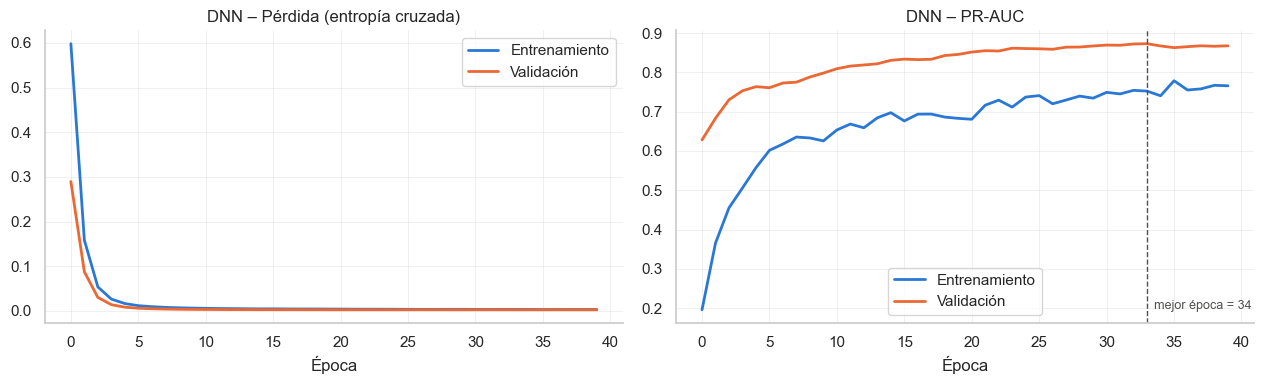

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (metrica, titulo) in zip(axes, [("loss", "Pérdida (entropía cruzada)"), ("pr_auc", "PR-AUC")]):
    ax.plot(historial_dnn[metrica], color=COLORES_BALANCEO["Sin balanceo"], linewidth=2, label="Entrenamiento")
    ax.plot(historial_dnn[f"val_{metrica}"], color=COLORES_BALANCEO["Pesos de clase"], linewidth=2, label="Validación")
    ax.set(title=f"DNN – {titulo}", xlabel="Época")
    ax.legend()
mejor_epoca = int(np.argmax(historial_dnn["val_pr_auc"]))
axes[1].axvline(mejor_epoca, color="#52514e", linestyle="--", linewidth=1)
axes[1].annotate(f"mejor época = {mejor_epoca + 1}", (mejor_epoca, axes[1].get_ylim()[0]),
                 xytext=(5, 10), textcoords="offset points", fontsize=9, color="#52514e")
plt.tight_layout()
guardar_figura("12_entrenamiento_dnn.png")
plt.show()

---
## 4.6 Autoencoder para detección de anomalías
El autoencoder se entrena **solo con las transacciones legítimas de entrenamiento** (la validación de su pérdida usa solo legítimas de validación). Luego se calcula el error de reconstrucción de todas las transacciones de validación. Se prueban cuatro arquitecturas y se elige la de mayor PR-AUC en validación. El umbral de alerta sobre el error se fija en la Fase 5.

In [11]:
Xs_train_normal = Xs_train[y_train.values == 0]
Xs_val_normal = Xs_val[y_val.values == 0]

filas, candidatos_ae = [], []
for capas in [(20, 10), (16, 8), (24, 12, 6), (28, 14, 7)]:
    inicio = time.perf_counter()
    ae, historial = tm.entrenar_autoencoder(Xs_train_normal, Xs_val_normal, capas=capas)
    error_val = tm.error_reconstruccion(ae, Xs_val)
    pr = average_precision_score(y_val, error_val)
    candidatos_ae.append((pr, capas, ae, historial))
    filas.append({"Arquitectura": f"31-{'-'.join(map(str, capas))}-...-31", "Cuello de botella": capas[-1],
                  "PR-AUC (val)": pr, "ROC-AUC (val)": roc_auc_score(y_val, error_val),
                  "Épocas": len(historial["loss"]), "MSE val (legítimas)": min(historial["val_loss"]),
                  "Tiempo (s)": time.perf_counter() - inicio})
display(pd.DataFrame(filas).sort_values("PR-AUC (val)", ascending=False).round(4))

pr_ae, capas_ae, autoencoder, historial_ae = max(candidatos_ae, key=lambda c: c[0])
error_val = tm.error_reconstruccion(autoencoder, Xs_val)
registrar("Autoencoder", error_val, tm.error_reconstruccion(autoencoder, Xs_test))
tm.guardar_modelo("Autoencoder", autoencoder, "autoencoder", "autoencoder.keras",
                  params={"capas": list(capas_ae)}, pr_auc_val=float(pr_ae))
print(f"Arquitectura elegida: {capas_ae} | PR-AUC val = {pr_ae:.4f}")

mediana = pd.Series(error_val).groupby(y_val.values).median()
print(f"Mediana del error: legítimas = {mediana[0]:.4f} | fraudes = {mediana[1]:.4f} "
      f"({mediana[1] / mediana[0]:.0f} veces mayor)")

,Arquitectura,Cuello de botella,PR-AUC (val),ROC-AUC (val),Épocas,MSE val (legítimas),Tiempo (s)
3,31-28-14-7-...-31,7,0.5833,0.9429,80,0.3235,60.5020
2,31-24-12-6-...-31,6,0.5694,0.9502,80,0.3456,55.1017
0,31-20-10-...-31,10,0.4571,0.9494,80,0.3288,53.7254
1,31-16-8-...-31,8,0.3652,0.9674,80,0.4402,53.0329


Arquitectura elegida: (28, 14, 7) | PR-AUC val = 0.5833
Mediana del error: legítimas = 0.2334 | fraudes = 8.5841 (37 veces mayor)


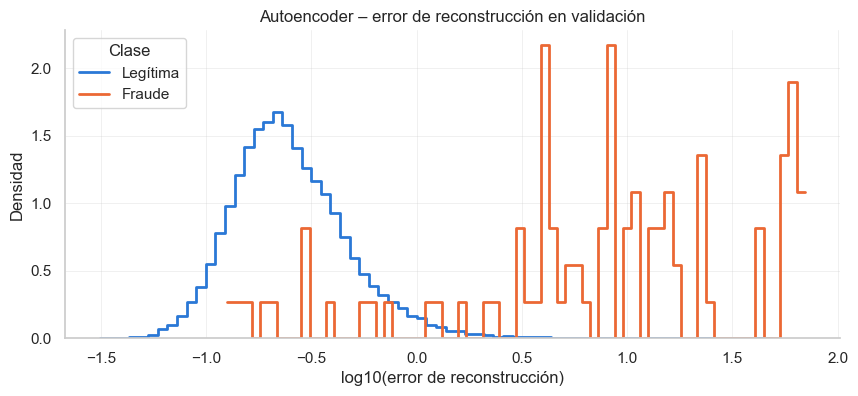

In [12]:
fig, ax = plt.subplots(figsize=(10, 4))
log_error = np.log10(error_val + 1e-9)
for clase in (0, 1):
    sns.histplot(log_error[y_val.values == clase], stat="density", bins=70, element="step",
                 fill=False, linewidth=2, color=PALETA_CLASES[clase], label=NOMBRES_CLASES[clase], ax=ax)
ax.set(xlabel="log10(error de reconstrucción)", ylabel="Densidad",
       title="Autoencoder – error de reconstrucción en validación")
ax.legend(title="Clase")
guardar_figura("13_autoencoder_error.png")
plt.show()

---
## 4.7 Resumen del modelado (validación)

In [13]:
finales = ["Regresión Logística", "Random Forest", "XGBoost", "Stacking (RF + XGB)", "DNN", "Autoencoder"]
registro = tm.cargar_registro()
resumen = pd.DataFrame([{
    "Modelo": m,
    "Balanceo": registro[m].get("balanceo", "—" if m != "Autoencoder" else "Solo legítimas"),
    "PR-AUC (val)": average_precision_score(y_val, puntajes_val[m]),
    "ROC-AUC (val)": roc_auc_score(y_val, puntajes_val[m]),
    "Archivo": registro[m]["archivo"],
} for m in finales]).set_index("Modelo")
if "Stacking (RF + XGB)" in resumen.index:
    resumen.loc["Stacking (RF + XGB)", "Balanceo"] = "Hereda de RF y XGB"
display(resumen.round(4))

tm.guardar_puntajes(puntajes_val, puntajes_test, splits["val"], splits["test"])
print(f"Puntajes guardados para {len(puntajes_val)} modelos/variantes en {tm.RUTA_PUNTAJES.relative_to(RAIZ)}")

,Balanceo,PR-AUC (val),ROC-AUC (val),Archivo
Modelo,,,,
Regresión Logística,SMOTE,0.8016,0.9797,logistica.joblib
Random Forest,SMOTE,0.8796,0.9652,random_forest.joblib
XGBoost,Sin balanceo,0.8892,0.9772,xgboost.joblib
Stacking (RF + XGB),Hereda de RF y XGB,0.8892,0.9709,stacking.joblib
DNN,Sin balanceo,0.8734,0.9651,dnn.keras
Autoencoder,Solo legítimas,0.5833,0.9429,autoencoder.keras


Puntajes guardados para 18 modelos/variantes en models\puntajes


---
# Resumen de la Fase 4

### Paso 1 · Estrategia de balanceo (PR-AUC en validación, hiperparámetros por defecto)

| Modelo | Sin balanceo | Pesos de clase | SMOTE | Elegida |
|---|---|---|---|---|
| Regresión Logística | 0,801 | 0,790 | **0,803** | SMOTE |
| Random Forest | 0,874 | 0,875 | **0,875** | SMOTE |
| XGBoost | **0,887** | 0,883 | 0,869 | Sin balanceo |
| DNN | **0,870** | 0,729 | 0,831 | Sin balanceo |

**Hallazgo.** El balanceo casi no cambia el PR-AUC de los modelos de árboles (diferencias menores a 0,02) e incluso lo empeora en XGBoost y, sobre todo, en la DNN con pesos de clase. El PR-AUC mide qué tan bien el modelo **ordena** las transacciones por riesgo; SMOTE y los pesos de clase desplazan sobre todo las probabilidades hacia arriba, lo que equivale a mover el umbral de decisión. Por eso, en la Fase 5, el umbral se optimiza para cada modelo en lugar de usar 0,5. En la DNN, los pesos de clase (≈ 300 veces más peso para el fraude) hacen el entrenamiento inestable: el *early stopping* se detuvo en la época 15.

### Paso 2 · Ajuste de hiperparámetros (`RandomizedSearchCV`, CV estratificada de 3 pliegues)

| Modelo | Mejores hiperparámetros | PR-AUC CV | PR-AUC val |
|---|---|---|---|
| Regresión Logística + SMOTE | `C` = 0,031; `sampling_strategy` = 0,05 | 0,734 ± 0,043 | 0,802 |
| Random Forest + SMOTE | 299 árboles, sin límite de profundidad, `max_features` = 0,3, `min_samples_leaf` = 3, `max_samples` = 0,5; `sampling_strategy` = 0,05 | 0,835 ± 0,062 | 0,880 |
| XGBoost | 543 árboles, `max_depth` = 7, `learning_rate` = 0,083, `subsample` = 0,68, `colsample_bytree` = 0,93, `gamma` = 1,2, `reg_lambda` = 4,6 | 0,837 ± 0,072 | **0,889** |

En ambos modelos con SMOTE la búsqueda eligió la proporción más baja (0,05): pocos sintéticos funcionan mejor que muchos. La desviación entre pliegues (0,04 – 0,07) es alta porque cada pliegue de validación tiene solo unos 95 fraudes; diferencias menores a ~0,02 entre modelos no son concluyentes.

### Modelos adicionales

- **Stacking (RF + XGB):** PR-AUC val = 0,889, igual que XGBoost solo. El meta-modelo reparte el peso de forma parecida entre ambos (coeficientes 6,9 para RF y 5,7 para XGB). La combinación no aporta mejora en ranking, pero cuesta el doble de cómputo.
- **DNN:** la mejor configuración fue la más pequeña, 32-16 con *dropout* 0,4 y `lr` = 10⁻³ (PR-AUC val = 0,873, 1 633 parámetros entrenables). Las redes más grandes no mejoraron, lo que es coherente con tener solo 284 fraudes de entrenamiento. El PR-AUC de entrenamiento queda por debajo del de validación porque durante el entrenamiento el *dropout* está activo.
- **Autoencoder:** la mejor arquitectura fue 31-28-14-7-14-28-31 (PR-AUC val = 0,583, ROC-AUC = 0,943). La mediana del error de reconstrucción de los fraudes es **37 veces mayor** que la de las legítimas, pero una parte de los fraudes se reconstruye tan bien como una transacción normal y queda mezclada con ellas. Es esperable: el autoencoder nunca ve un fraude y no puede aprender qué lo distingue. Su valor es complementario: puede detectar patrones de fraude nuevos que los modelos supervisados no conocen. Las cuatro arquitecturas usaron las 80 épocas, así que con más épocas podría mejorar algo.

### Resumen (validación)

| Modelo | Balanceo | PR-AUC (val) | ROC-AUC (val) |
|---|---|---|---|
| XGBoost | Sin balanceo | **0,889** | 0,977 |
| Stacking (RF + XGB) | Hereda de RF y XGB | **0,889** | 0,971 |
| Random Forest | SMOTE (0,05) | 0,880 | 0,965 |
| DNN | Sin balanceo | 0,873 | 0,965 |
| Regresión Logística | SMOTE (0,05) | 0,802 | 0,980 |
| Autoencoder | Solo legítimas | 0,583 | 0,943 |

La Regresión Logística tiene el ROC-AUC más alto y el PR-AUC más bajo de los supervisados: un ejemplo de por qué el ROC-AUC solo es engañoso con este desbalance.

**Artefactos:** 6 modelos en `models/` (`logistica.joblib`, `random_forest.joblib`, `xgboost.joblib`, `stacking.joblib`, `dnn.keras`, `autoencoder.keras`), `models/registro_modelos.json` con hiperparámetros y métricas, y los puntajes de 18 modelos y variantes en `models/puntajes/` para la Fase 5.